# Exploratory overview — `2011.csv` (BRFSS 2011)

This file is the CDC **Behavioral Risk Factor Surveillance System** 2011 survey: one row per respondent, one column per question or derived variable.

**Goal:** get a general feel for the data — size, types, missing values, and the distribution of a handful of key health variables.

> ⚠️ BRFSS uses **special codes** instead of NaN: `7` / `77` / `777` = *don't know*, `9` / `99` / `999` = *refused*, and `88` = *none* (e.g. 0 days). We decode these before plotting.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)

# Colour palette (colour-blind-checked categorical order)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6f42c1']
BLUE = PALETTE[0]
sns.set_theme(style='whitegrid', palette=PALETTE)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#e6e6e3', 'axes.edgecolor': '#999'})

# Folder where the figures are saved (used later in the README)
os.makedirs('images', exist_ok=True)
def save(name):
    plt.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')

## 1. Load the data

The file is large (~700 MB), so loading takes a little while.

In [2]:
df = pd.read_csv('2011.csv', low_memory=False)
print(f'{df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')

506,467 rows × 454 columns
Memory: 1.87 GB


In [3]:
df.head()

,_STATE,_GEOSTR,_DENSTR2,PRECALL,REPNUM,REPDEPTH,FMONTH,IDATE,IMONTH,IDAY,IYEAR,INTVID,DISPCODE,SEQNO,_PSU,NATTMPTS,NRECSEL,NRECSTR,CTELENUM,CELLFON,PVTRESID,NUMADULT,NUMMEN,NUMWOMEN,GENHLTH,...,PAVIGM1_,PAVIGM2_,PAVIGMN_,_PACAT,_PAINDEX,_PA150R1,_PA300R1,_PA3002L,_PASTRNG,_PAREC,_PASTAER,_RFSEAT2,_RFSEAT3,_FLSHOT5,_PNEUMO2,DRNKANY5,DROCDY3_,_RFBING5,_DRNKDY4,_DRNKMO4,_RFDRHV4,_RFDRMN4,_RFDRWM4,_AIDTST3,HAVHPAD
0,1.0,1.0,1.0,1.0,10001.0,27.0,1.0,b'01202011',b'01',b'20',b'2011',b'00118',120.0,2.011000e+09,2.011000e+09,6.0,1662.0,56365.0,1.0,1.0,1.0,2.0,1.000000e+00,1.0,4.0,...,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,NaN,NaN,1.0,4.300000e+01,1.0,8.600000e+01,2.600000e+01,1.0,NaN,1.0,2.0,NaN
1,1.0,1.0,1.0,1.0,10008.0,13.0,1.0,b'01142011',b'01',b'14',b'2011',b'00136',120.0,2.011000e+09,2.011000e+09,6.0,1662.0,56365.0,1.0,1.0,1.0,4.0,3.000000e+00,1.0,4.0,...,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,9.0,9.0,NaN,NaN,9.0,9.000000e+02,9.0,9.900000e+03,9.999000e+03,9.0,9.0,NaN,NaN,NaN
2,1.0,5.0,1.0,1.0,10058.0,4.0,1.0,b'01062011',b'01',b'06',b'2011',b'00140',120.0,2.011001e+09,2.011001e+09,1.0,1689.0,113769.0,1.0,1.0,1.0,1.0,5.397605e-79,1.0,2.0,...,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,2.0,9.0,9.0,1.0,1.0,9.0,9.0,1.0,1.400000e+01,1.0,1.400000e+01,4.000000e+00,1.0,NaN,1.0,2.0,NaN
3,1.0,7.0,1.0,1.0,10079.0,7.0,1.0,b'02012011',b'02',b'01',b'2011',b'00188',120.0,2.011001e+09,2.011001e+09,15.0,2088.0,41627.0,1.0,1.0,1.0,2.0,1.000000e+00,1.0,3.0,...,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.000000e+02,9.0,9.900000e+03,9.999000e+03,9.0,NaN,9.0,NaN,NaN
4,1.0,7.0,1.0,1.0,10081.0,28.0,1.0,b'02012011',b'02',b'01',b'2011',b'00118',120.0,2.011001e+09,2.011001e+09,14.0,2088.0,41627.0,1.0,1.0,1.0,2.0,1.000000e+00,1.0,5.0,...,5.397605e-79,5.397605e-79,5.397605e-79,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,NaN,NaN,2.0,5.397605e-79,1.0,5.397605e-79,5.397605e-79,1.0,NaN,1.0,1.0,NaN


## 2. Column types

Almost everything is numeric (answers are stored as codes). The few text columns are mostly dates.

In [4]:
print(df.dtypes.value_counts())
print('\nNon-numeric columns:', df.select_dtypes(exclude='number').columns.tolist())

float64    444
str         10
Name: count, dtype: int64

Non-numeric columns: ['IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'INTVID', 'MRACE', 'RCSBIRTH', 'RCSRACE', 'RCVFVCH4', 'MRACEORG']


In [5]:
# Clean the date column into a real date (works whether it is stored as '01292011' or b'01292011')
s = df['IDATE'].astype(str).str.replace("b'", '', regex=False).str.replace("'", '', regex=False).str.strip()
df['IDATE'] = pd.to_datetime(s, format='%m%d%Y', errors='coerce')
df['IDATE'].describe()

count                        506404
mean     2011-07-04 17:38:43.119090
min             2011-01-02 00:00:00
25%             2011-04-08 00:00:00
50%             2011-07-07 00:00:00
75%             2011-10-05 00:00:00
max             2012-02-01 00:00:00
Name: IDATE, dtype: object

## 3. Missing values

With hundreds of columns, many questions were only asked in some states or to some respondents (optional modules), so missingness is high for a lot of columns.

In [6]:
missing = df.isna().mean().sort_values(ascending=False)
print(f'Overall missing cells: {df.isna().mean().mean():.1%}')
print(f'Columns with no missing values: {(missing == 0).sum()}')
print(f'Columns more than 50% missing: {(missing > 0.5).sum()}')
print(f'Columns more than 90% missing: {(missing > 0.9).sum()}')

Overall missing cells: 54.2%
Columns with no missing values: 96
Columns more than 50% missing: 250
Columns more than 90% missing: 212


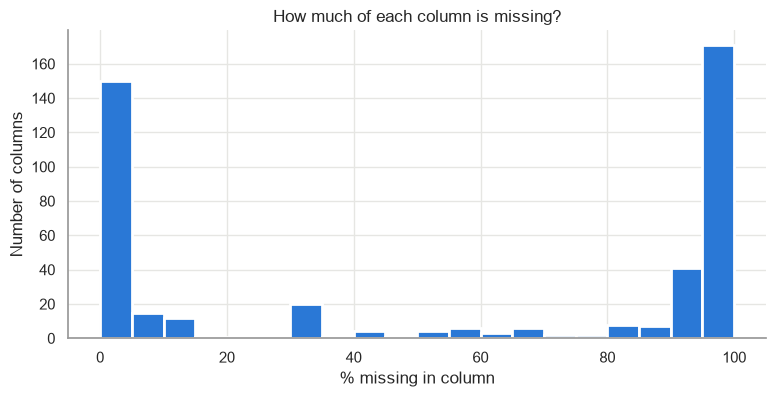

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(missing * 100, bins=20, color=BLUE, edgecolor='white', linewidth=2)
ax.set(title='How much of each column is missing?', xlabel='% missing in column', ylabel='Number of columns')
save('missing_values_hist')
plt.show()

In [8]:
missing.head(15).to_frame('fraction_missing')

,fraction_missing
HAVHPAD,1.0
EMTSUPRT,1.0
LSATISFY,1.0
HIVRDTS2,1.0
WHRTST9,1.0
RRCOGNT2,1.0
GPEMRIN1,1.0
GPVACPL1,1.0
GPMNDEVC,1.0
GPNOTEV1,1.0


## 4. A focused subset of key variables

Hundreds of columns are too many to look at one by one. Here are 14 widely used ones. Their meanings come from the **BRFSS 2011 codebook**:

| Column | Meaning |
|---|---|
| `GENHLTH` | General health (1 = Excellent … 5 = Poor) |
| `PHYSHLTH` / `MENTHLTH` | Days of poor physical / mental health in the past 30 days |
| `_BMI5` | Body mass index × 100 |
| `SEX` | 1 = Male, 2 = Female |
| `_AGEG5YR` | Age in 5-year groups (1 = 18–24 … 13 = 80+) |
| `_EDUCAG`, `_INCOMG` | Education level, income group |
| `_SMOKER3` | Smoking status |
| `DIABETE3`, `_RFHYPE5`, `CVDINFR4` | Diabetes, high blood pressure, heart attack ever |
| `EXERANY2` | Any exercise in the past month |
| `_STATE` | State FIPS code |

In [9]:
# Check that every column used below exists in the 2011 file.
# Some names change from one year to another, so we look for the first one that exists.
def pick(*names):
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f'None of {names} found. Search with: [c for c in df.columns if "DIAB" in c]')

TARGET = pick('DIABETE3', 'DIABETE2')   # diabetes question
BMI_COL = pick('_BMI5', '_BMI4')        # BMI x 100
print('Diabetes column :', TARGET)
print('BMI column      :', BMI_COL)

cols = ['_STATE', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', BMI_COL, 'SEX', '_AGEG5YR', '_EDUCAG',
        '_INCOMG', '_SMOKER3', TARGET, '_RFHYPE5', 'CVDINFR4', 'EXERANY2']

absent = [c for c in cols if c not in df.columns]
print('Missing columns :', absent if absent else 'none, all good')

Diabetes column : DIABETE3
BMI column      : _BMI5
Missing columns : none, all good


In [10]:
d = df[cols].copy()

# --- Decode the special codes ---
for c in ['GENHLTH', TARGET, 'CVDINFR4', 'EXERANY2']:
    d[c] = d[c].replace({7: np.nan, 9: np.nan})
for c in ['PHYSHLTH', 'MENTHLTH']:
    d[c] = d[c].replace({88: 0, 77: np.nan, 99: np.nan})
d['_AGEG5YR'] = d['_AGEG5YR'].replace({14: np.nan})
for c in ['_EDUCAG', '_INCOMG', '_SMOKER3', '_RFHYPE5']:
    d[c] = d[c].replace({9: np.nan})
d['BMI'] = d.pop(BMI_COL) / 100

# --- Readable labels ---
d['SEX'] = d['SEX'].map({1: 'Male', 2: 'Female'})
d['GENHLTH'] = d['GENHLTH'].map({1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'})
d[TARGET] = d[TARGET].map({1: 'Yes', 2: 'Yes (pregnancy only)', 3: 'No', 4: 'Pre-diabetes'})
d['_SMOKER3'] = d['_SMOKER3'].map({1: 'Daily smoker', 2: 'Some days', 3: 'Former smoker', 4: 'Never smoked'})
d['_RFHYPE5'] = d['_RFHYPE5'].map({1: 'No', 2: 'Yes'})   # 2 = has high blood pressure
d['CVDINFR4'] = d['CVDINFR4'].map({1: 'Yes', 2: 'No'})
d['EXERANY2'] = d['EXERANY2'].map({1: 'Yes', 2: 'No'})
age_labels = ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59',
              '60-64', '65-69', '70-74', '75-79', '80+']
d['AGE'] = pd.Categorical(d.pop('_AGEG5YR').map(dict(enumerate(age_labels, 1))),
                          categories=age_labels, ordered=True)
d.head()

,_STATE,GENHLTH,PHYSHLTH,MENTHLTH,SEX,_EDUCAG,_INCOMG,_SMOKER3,DIABETE3,_RFHYPE5,CVDINFR4,EXERANY2,BMI,AGE
0,1.0,Fair,0.0,30.0,Female,2.0,2.0,Daily smoker,No,Yes,No,No,18.55,60-64
1,1.0,Fair,12.0,4.0,Male,1.0,3.0,Daily smoker,No,Yes,No,No,35.29,30-34
2,1.0,Very good,0.0,3.0,Female,4.0,3.0,Former smoker,No,Yes,No,Yes,16.95,NaN
3,1.0,Good,0.0,0.0,Female,2.0,NaN,Never smoked,No,No,No,NaN,25.79,NaN
4,1.0,Poor,25.0,15.0,Female,1.0,1.0,Former smoker,Pre-diabetes,Yes,No,Yes,43.46,50-54


### 4.1 Numeric summary

In [11]:
d[['BMI', 'PHYSHLTH', 'MENTHLTH']].describe().round(2)

,BMI,PHYSHLTH,MENTHLTH
count,478839.00,494280.00,496702.00
mean,27.67,4.36,3.47
std,6.03,8.87,7.80
min,12.02,0.00,0.00
25%,23.62,0.00,0.00
50%,26.63,0.00,0.00
75%,30.55,3.00,2.00
max,97.65,30.00,30.00


### 4.2 Distributions of numeric variables

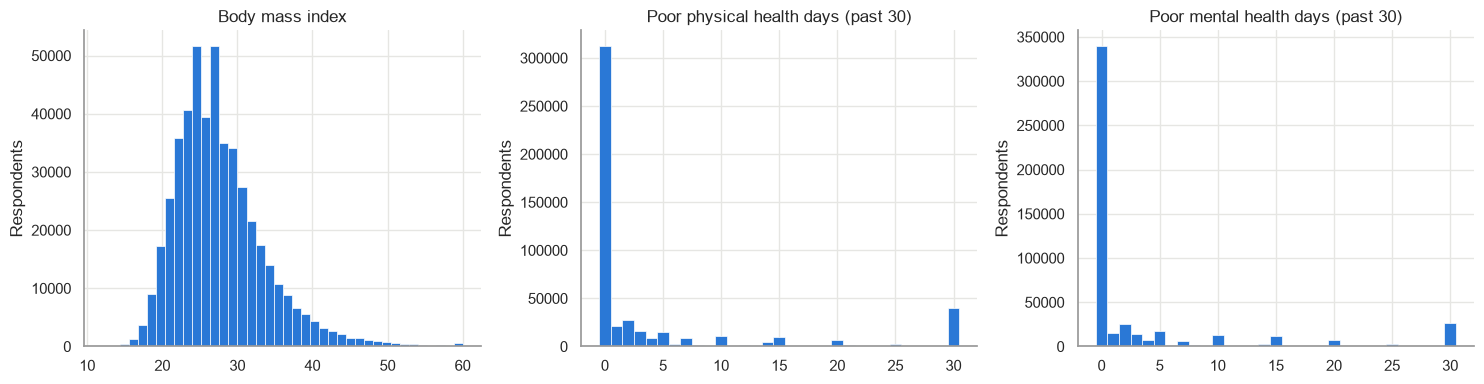

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
specs = [('BMI', 'Body mass index', (12, 60)),
         ('PHYSHLTH', 'Poor physical health days (past 30)', (0, 30)),
         ('MENTHLTH', 'Poor mental health days (past 30)', (0, 30))]
for ax, (c, title, rng) in zip(axes.flat, specs):
    bins = 40 if c == 'BMI' else np.arange(rng[0], rng[1] + 2) - 0.5
    ax.hist(d[c].dropna().clip(*rng), bins=bins, color=BLUE, edgecolor='white', linewidth=0.5)
    ax.set(title=title, ylabel='Respondents')
plt.tight_layout()
save('numeric_distributions')
plt.show()

**What to notice:** most people report **0** bad health days, with a spike at 30 (chronic issues). BMI is right-skewed.

### 4.3 Categorical variables

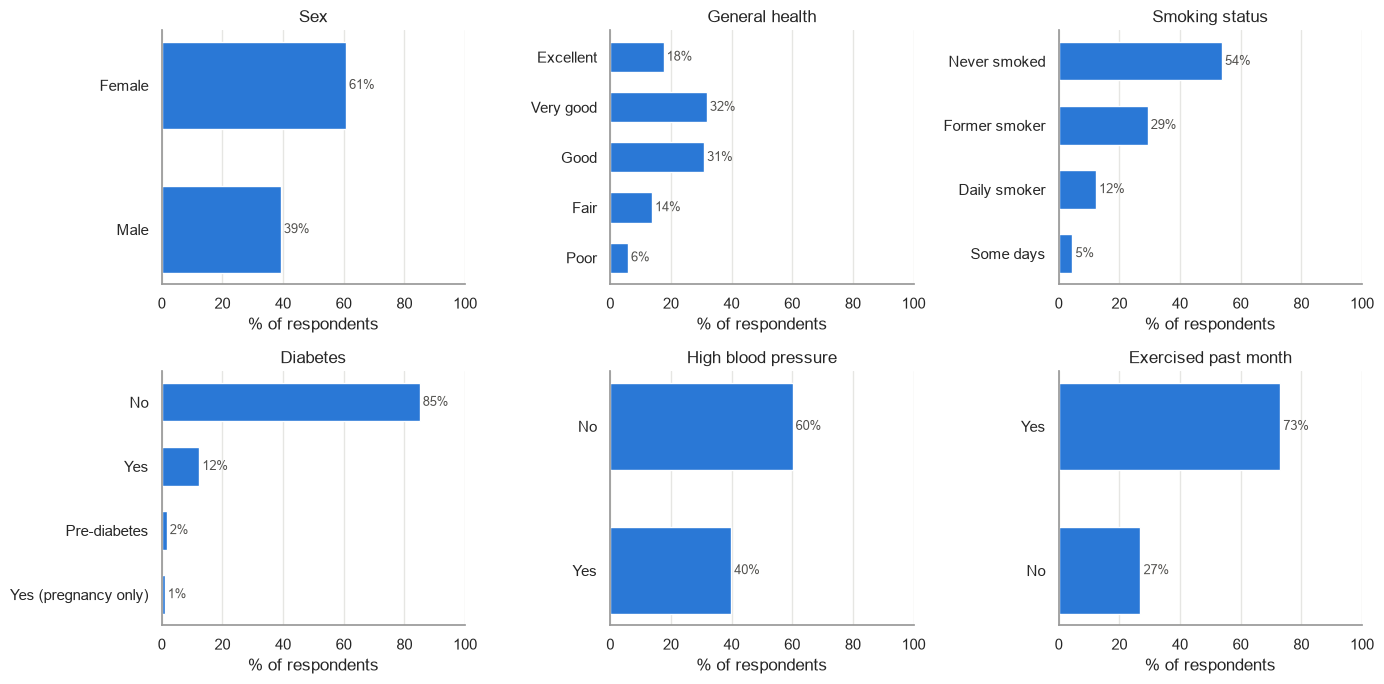

In [13]:
cat_cols = ['SEX', 'GENHLTH', '_SMOKER3', TARGET, '_RFHYPE5', 'EXERANY2']
titles = ['Sex', 'General health', 'Smoking status', 'Diabetes', 'High blood pressure', 'Exercised past month']
order = {'GENHLTH': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c, t in zip(axes.flat, cat_cols, titles):
    vc = d[c].value_counts(normalize=True) * 100
    if c in order:
        vc = vc.reindex(order[c])
    ax.barh(vc.index[::-1], vc.values[::-1], color=BLUE, height=0.6)
    for y, v in enumerate(vc.values[::-1]):
        ax.text(v + 1, y, f'{v:.0f}%', va='center', fontsize=9, color='#52514e')
    ax.set(title=t, xlim=(0, 100))
    ax.set_xlabel('% of respondents')
    ax.grid(axis='y', visible=False)
plt.tight_layout()
save('categorical_variables')
plt.show()

### 4.4 Who answered? Age distribution

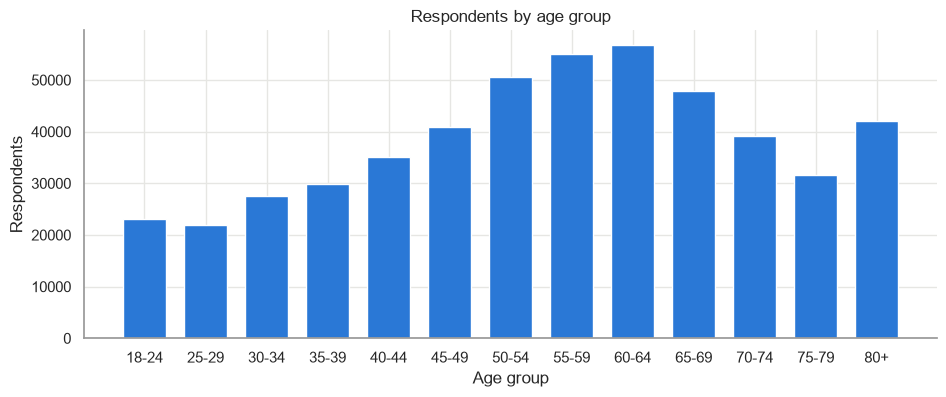

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
vc = d['AGE'].value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.7)
ax.set(title='Respondents by age group', xlabel='Age group', ylabel='Respondents')
save('age_distribution')
plt.show()

The survey leans older: there are more respondents aged 50–74 than young adults. Keep this in mind, because raw averages over-represent older people. BRFSS provides a weight column (`_LLCPWT` or `_FINALWT`, check the 2011 codebook) to correct for that.

## 5. Relationships between variables

### 5.1 Correlation between numeric/ordinal variables

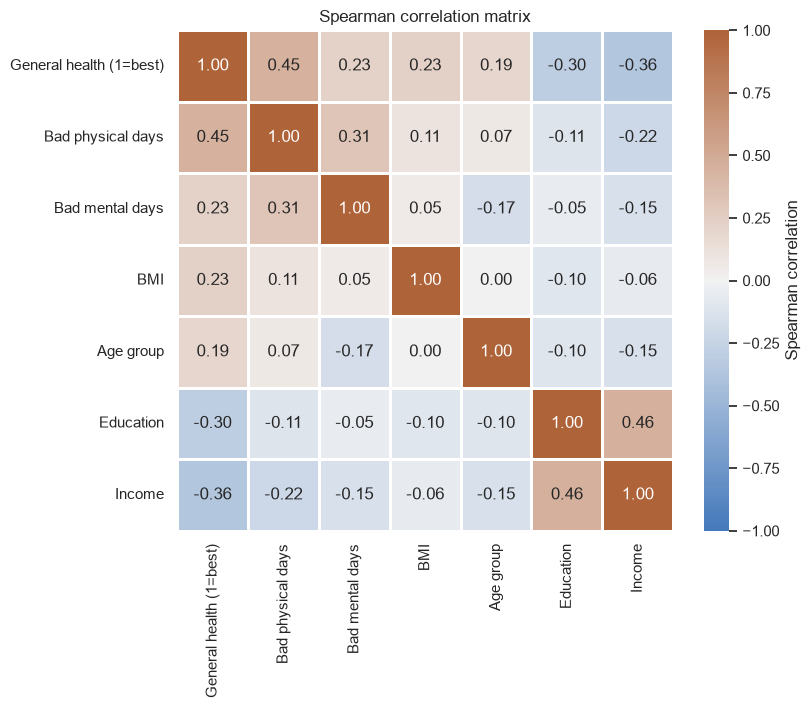

In [15]:
num = df[cols].copy()
num['GENHLTH'] = num['GENHLTH'].replace({7: np.nan, 9: np.nan})
for c in ['PHYSHLTH', 'MENTHLTH']:
    num[c] = num[c].replace({88: 0, 77: np.nan, 99: np.nan})
num['_AGEG5YR'] = num['_AGEG5YR'].replace({14: np.nan})
for c in ['_EDUCAG', '_INCOMG']:
    num[c] = num[c].replace({9: np.nan})
num['BMI'] = num.pop(BMI_COL) / 100

num = num[['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'BMI', '_AGEG5YR', '_EDUCAG', '_INCOMG']]
num.columns = ['General health (1=best)', 'Bad physical days', 'Bad mental days',
               'BMI', 'Age group', 'Education', 'Income']

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap=sns.diverging_palette(250, 30, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor='white', cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Spearman correlation matrix')
save('correlation_heatmap')
plt.show()

Higher `GENHLTH` means *worse* health, so a positive correlation with bad-health days makes sense. Negative correlations with income and education mean that richer and more educated respondents tend to report better health.

### 5.2 Self-rated health by income group

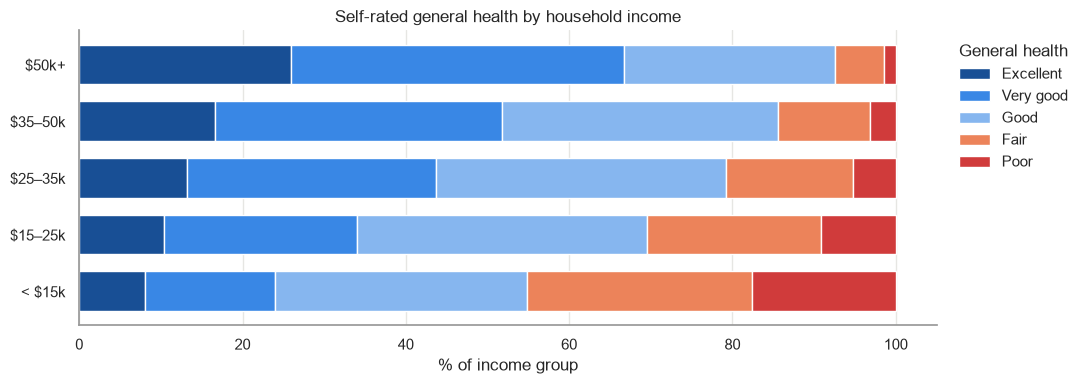

In [16]:
inc_labels = {1: '< $15k', 2: '$15–25k', 3: '$25–35k', 4: '$35–50k', 5: '$50k+'}
tmp = pd.DataFrame({'Income': df['_INCOMG'].map(inc_labels), 'Health': d['GENHLTH']}).dropna()
ct = (pd.crosstab(tmp['Income'], tmp['Health'], normalize='index')
        .reindex(list(inc_labels.values()))[['Excellent', 'Very good', 'Good', 'Fair', 'Poor']] * 100)
seq = ['#184f95', '#3987e5', '#86b6ef', '#ec835a', '#d03b3b']   # good (blue) -> poor (red)
ax = ct.plot(kind='barh', stacked=True, figsize=(11, 4), color=seq, width=0.7, edgecolor='white')
ax.set(title='Self-rated general health by household income', xlabel='% of income group', ylabel='')
ax.legend(title='General health', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
ax.grid(axis='y', visible=False)
plt.tight_layout()
save('health_by_income')
plt.show()

### 5.3 BMI and chronic conditions

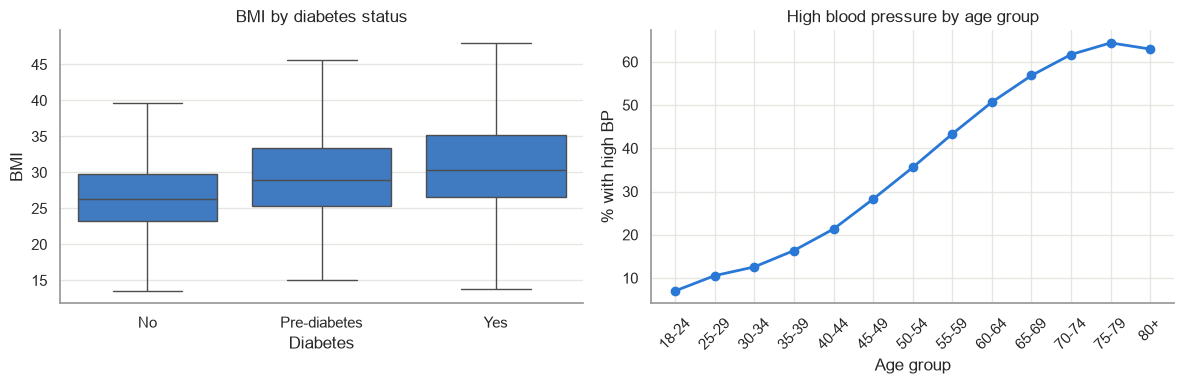

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sub = d[d[TARGET].isin(['Yes', 'No', 'Pre-diabetes'])]
sns.boxplot(data=sub, x=TARGET, y='BMI', order=['No', 'Pre-diabetes', 'Yes'], color=BLUE,
            showfliers=False, ax=axes[0])
axes[0].set(title='BMI by diabetes status', xlabel='Diabetes', ylabel='BMI')

rate = d.groupby('AGE', observed=True)['_RFHYPE5'].apply(lambda s: (s == 'Yes').sum() / s.notna().sum() * 100)
axes[1].plot(rate.index.astype(str), rate.values, color=BLUE, lw=2, marker='o')
axes[1].set(title='High blood pressure by age group', xlabel='Age group', ylabel='% with high BP')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
save('bmi_diabetes_bp')
plt.show()

### 5.4 Respondents per state

53 states/territories; median 8,259 respondents each


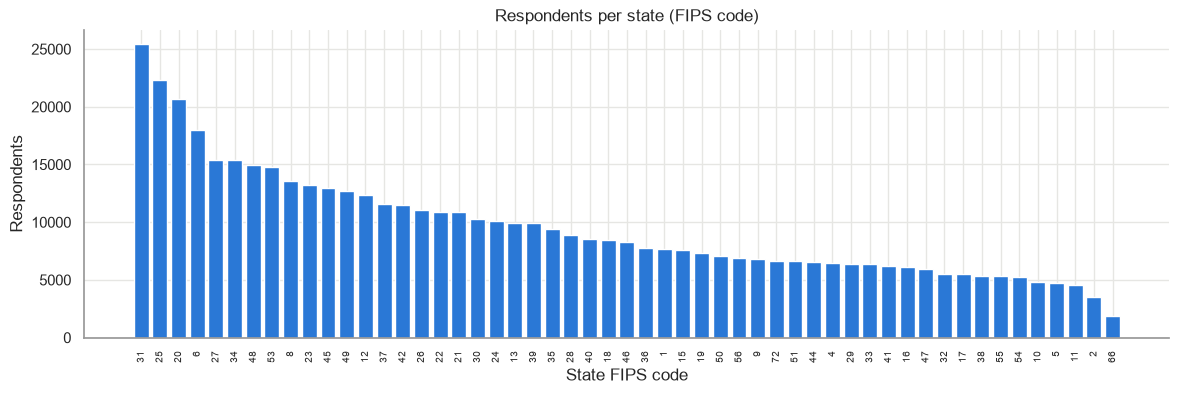

In [18]:
state_counts = df['_STATE'].value_counts()
print(f'{state_counts.size} states/territories; median {state_counts.median():,.0f} respondents each')

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(state_counts.index.astype(int).astype(str), state_counts.values, color=BLUE)
ax.set(title='Respondents per state (FIPS code)', xlabel='State FIPS code', ylabel='Respondents')
ax.tick_params(axis='x', rotation=90, labelsize=7)
save('respondents_per_state')
plt.show()

## 6. Takeaways

Fill in the numbers after running the notebook (they come from the outputs above):

- **Large and wide:** *N* respondents × *M* variables. Most columns are numeric codes, so you need the BRFSS 2011 codebook to read them.
- **Special codes matter:** values like 7/9/77/88/99 must be recoded before analysis, or means and correlations will be wrong.
- **Lots of structural missingness:** many columns come from optional modules and are more than 90% empty. Pick a subset of columns that suits your question.
- **Clear patterns:** health worsens with age, lower income and higher BMI; bad-health days are bimodal (0 or 30).
- **Survey weights:** the sample is skewed toward older adults. Use the weight column if you need population-level estimates.

**Possible next steps:** choose the diabetes column as target for a classification model, then select and clean the relevant features.

## 7. Quick check: empty values, cleaning, and relations between columns

This section only reads the data. Nothing in the CSV file is modified.

### 7.1 How many empty values?

In [19]:
total_cells = df.size
empty_cells = df.isna().sum().sum()
print(f'Total cells        : {total_cells:,}')
print(f'Empty (NaN) cells  : {empty_cells:,} ({empty_cells / total_cells:.1%})')
print(f'Rows with no empty : {(~df.isna().any(axis=1)).sum():,} of {len(df):,}')
print(f'Duplicate rows     : {df.duplicated().sum():,}')

# Empty values per column, sorted (the 20 emptiest)
df.isna().sum().sort_values(ascending=False).head(20).to_frame('empty_values')

Total cells        : 229,936,018
Empty (NaN) cells  : 124,708,640 (54.2%)
Rows with no empty : 0 of 506,467
Duplicate rows     : 0


,empty_values
HAVHPAD,506467
EMTSUPRT,506467
LSATISFY,506467
HIVRDTS2,506467
WHRTST9,506467
RRCOGNT2,506467
GPEMRIN1,506467
GPVACPL1,506467
GPMNDEVC,506467
GPNOTEV1,506467


### 7.2 Hidden missing values (special codes)

Some answers are not NaN, but they mean *don't know* or *refused* (7/9, 77/99). They look like real numbers, so you need to recode them as well.

In [20]:
hidden = {c: df[c].isin([7, 9]).sum() for c in ['GENHLTH', TARGET, 'CVDINFR4', 'EXERANY2', '_SMOKER3',
                                                '_RFHYPE5', '_INCOMG', '_EDUCAG']}
hidden.update({c: df[c].isin([77, 99]).sum() for c in ['PHYSHLTH', 'MENTHLTH']})
pd.Series(hidden, name='hidden_missing (coded 7/9/77/99)').to_frame()

,hidden_missing (coded 7/9/77/99)
GENHLTH,2009
DIABETE3,811
CVDINFR4,2464
EXERANY2,2269
_SMOKER3,2542
_RFHYPE5,1370
_INCOMG,73575
_EDUCAG,1928
PHYSHLTH,12186
MENTHLTH,9765


### 7.3 Do I need to clean it?

Yes, for the same reasons as in other years:

- A large share of all cells is empty and no row is complete, so you can't just call `dropna()`. Drop the columns that are mostly empty and keep the ones relevant to your question.
- Special codes (7, 9, 77, 99, 88) must be recoded, or they will distort averages and models.
- Check for duplicate rows (see the count above).

### 7.4 Is there a relation between the columns?

In [21]:
num = df.select_dtypes('number')
num = num.loc[:, (num.isna().mean() < 0.5) & (num.nunique() > 1)]
corr = num.sample(50_000, random_state=0).corr(method='spearman').abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)

print(f'Columns compared        : {num.shape[1]}')
print(f'Pairs compared          : {len(pairs):,}')
print(f'Very strong (|r| > 0.9) : {(pairs > 0.9).sum()}')
print(f'Moderate+   (|r| > 0.5) : {(pairs > 0.5).sum()}')
pairs.head(20).rename('abs_spearman').to_frame()

Columns compared        : 192
Pairs compared          : 36,864
Very strong (|r| > 0.9) : 105
Moderate+   (|r| > 0.5) : 363


,,abs_spearman
HAVARTH3,_DRDXAR1,1.000000
_REGION,_LLCPM09,1.000000
HEIGHT3,HTIN4,1.000000
HTIN4,HTM4,1.000000
_RFDRHV4,_RFDRWM4,1.000000
SEQNO,_PSU,1.000000
EXERHMM1,PADUR1_,1.000000
EXERANY2,_TOTINDA,1.000000
MAXVO2_,FC60_,0.999998
HIVTST6,_AIDTST3,0.999984


In [22]:
counts = df['DIABETE3'].value_counts(dropna=False).sort_index()
print(counts)
print((counts / len(df) * 100).round(1))

DIABETE3
1.0     62461
2.0      4828
3.0    429062
4.0      8179
7.0       602
9.0       209
NaN      1126
Name: count, dtype: int64
DIABETE3
1.0    12.3
2.0     1.0
3.0    84.7
4.0     1.6
7.0     0.1
9.0     0.0
NaN     0.2
Name: count, dtype: float64


**Reading the result:** most strong correlations are duplicates, because BRFSS stores the raw answer and a derived version of it (for example `EDUCA` ↔ `_EDUCAG`, or height in different units). These pairs carry the same information, so **keep only one of each** for modelling.